In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import GroupShuffleSplit, GridSearchCV
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
from sklearn.tree import plot_tree
from google.colab import drive
drive.mount('/content/drive')
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight
import tensorflow.keras.backend as K
from tensorflow.keras.losses import binary_crossentropy
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

Mounted at /content/drive


In [ ]:
# načítanie datasetov
file_paths = [
    "/content/drive/MyDrive/Colab Notebooks/Friday-WorkingHours-Morning.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Wednesday-workingHours.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Tuesday-WorkingHours.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "/content/drive/MyDrive/Colab Notebooks/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv"
]

In [ ]:
flow_features = [
    'Destination Port', 'Flow Duration',
    'Total Fwd Packets', 'Total Backward Packets',
    'Fwd Header Length', 'Bwd Header Length'
]

In [ ]:
selected_features = [
    'Average Packet Size', 'Max Packet Length', 'Avg Bwd Segment Size',
    'Bwd Packet Length Max', 'Packet Length Mean',
    'Bwd Packet Length Std', 'Packet Length Variance',
    'Avg Fwd Segment Size', 'Bwd Packet Length Mean', 'Packet Length Std',
    'Subflow Fwd Bytes', 'Fwd Packet Length Max',
    'Fwd Packet Length Min', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets'
]

In [ ]:
dataframes = []
for file in file_paths:
    df = pd.read_csv(file)
    df.columns = df.columns.str.strip()
    if df['Label'].dtype == object:
        df['Label'] = df['Label'].apply(lambda x: 0 if isinstance(x, str) and "BENIGN" in x.upper() else 1)
    else:
        df['Label'] = df['Label'].apply(lambda x: 0 if x == 0 else 1)
    dataframes.append(df)

df = pd.concat(dataframes, ignore_index=True)
df['Flow_ID'] = df[flow_features].astype(str).agg('-'.join, axis=1)

In [ ]:
gss = GroupShuffleSplit(test_size=0.3, n_splits=1, random_state=42)
train_idx, test_idx = next(gss.split(df, groups=df['Flow_ID']))
train_df = df.iloc[train_idx]
test_df = df.iloc[test_idx]

X_train = train_df[selected_features]
y_train = train_df['Label']
X_test = test_df[selected_features]
y_test = test_df['Label']

In [ ]:
# čistenie
X_train = X_train.replace([np.inf, -np.inf], np.nan).fillna(0)
X_test = X_test.replace([np.inf, -np.inf], np.nan).fillna(0)

In [ ]:
# škálovanie
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
def focal_loss(gamma=2., alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        BCE = binary_crossentropy(y_true, y_pred)
        pt = K.exp(-BCE)
        return alpha * (1 - pt) ** gamma * BCE
    return focal_loss_fixed

In [ ]:
# definovanie a trénovanie NN modelu
model = models.Sequential([
    layers.Dense(256, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(1, activation='sigmoid')
])


optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)
model.compile(optimizer=optimizer, loss=focal_loss(gamma=2., alpha=0.25), metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(
    X_train_scaled, y_train,
    epochs=30, batch_size=512,
    validation_split=0.1,
    verbose=1,
    class_weight = {0: 1.0, 1: 2.0},
    callbacks=[early_stop]
)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
2852/2852 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.7870 - loss: 0.0333 - val_accuracy: 0.8805 - val_loss: 0.0122
Epoch 2/30
2852/2852 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.8107 - loss: 0.0240 - val_accuracy: 0.8806 - val_loss: 0.0104
Epoch 3/30
2852/2852 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.8153 - loss: 0.0229 - val_accuracy: 0.8802 - val_loss: 0.0123
Epoch 4/30
2852/2852 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.8462 - loss: 0.0210 - val_accuracy: 0.8747 - val_loss: 0.0102
Epoch 5/30
2852/2852 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.8730 - loss: 0.0189 - val_accuracy: 0.8764 - val_loss: 0.0100
Epoch 6/30
2852/2852 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.8941 - loss: 0.0171 - val_accuracy: 0.8717 - val_loss: 0.0123
Epoch 7/30
2852/2852 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9014 - loss: 0.0160 - val_accuracy: 0.9818 - val_loss: 0.0075
Epoch 8/30
2852/2852 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9046 - loss: 0.0152 -

In [ ]:
# model RF
rf_model = RandomForestClassifier(
    class_weight="balanced",
    max_depth=20,
    max_features='log2',
    min_samples_leaf=1,
    min_samples_split=5,
    n_estimators=100,
    oob_score=True,
    random_state=42
)

In [ ]:
rf_model.fit(X_train_scaled, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=20,
                       max_features='log2', min_samples_split=5, oob_score=True,
                       random_state=42)

In [ ]:
# pôvodné pravdepodobnosti
rf_probs = rf_model.predict_proba(X_test_scaled)[:, 1]
nn_probs = model.predict(X_test_scaled).flatten()

# Normalizácia podľa individuálnych optimálnych thresholdov
rf_probs_adj = rf_probs / 0.6
nn_probs_adj = nn_probs / 0.5

# soft voting
ensemble_probs = 0.5 * rf_probs_adj + 0.5 * nn_probs_adj
ensemble_preds = (ensemble_probs >= 1.0).astype(int)


# Vyhodnotenie
from sklearn.metrics import classification_report, roc_auc_score
print(classification_report(y_test, ensemble_preds))
print(f"Ensemble ROC AUC: {roc_auc_score(y_test, ensemble_probs):.4f}")

21210/21210 ━━━━━━━━━━━━━━━━━━━━ 26s 1ms/step
              precision    recall  f1-score   support

           0       0.98      1.00      0.99    524456
           1       0.99      0.93      0.96    154241

    accuracy                           0.98    678697
   macro avg       0.98      0.96      0.97    678697
weighted avg       0.98      0.98      0.98    678697

Ensemble ROC AUC: 0.9946


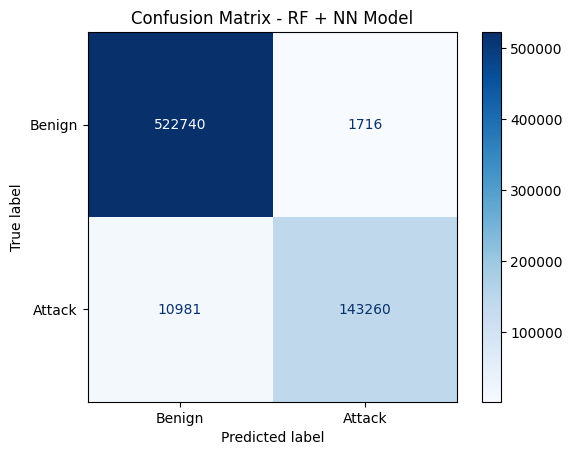

In [ ]:
# confusion matrix
cm = confusion_matrix(y_test, ensemble_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign', 'Attack'])
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix - RF + NN Model')
plt.grid(False)
plt.show()